# E3 — Khi nào nên retrain? Tín hiệu nào phát hiện drift tốt nhất?

**Notebook học theo từng bước** của giai đoạn 5. Đọc cùng: [`../PHUONG-PHAP.md`](../PHUONG-PHAP.md) (khung 7 bước) và [`../E1-chi-so-danh-gia.md`](../E1-chi-so-danh-gia.md) (đã chọn họ MAE/WAPE để theo dõi).

**Cách dùng trong VS Code:** chọn kernel `.venv`, chạy từng ô bằng **Shift + Enter**. Mỗi phần có: **Đang làm gì** → **Đoán trước** → ô code → **Đọc kết quả**.

| Bước nhỏ | Nội dung | Trạng thái |
| --- | --- | --- |
| **5.1** | Chạy lại đúng cách phát hiện drift của hệ thống trên dữ liệu thật | Đang làm |
| **5.2** | Dựng "đáp án": tuần nào model thật sự cần retrain | Chưa |
| **5.3** | Tính 5 tín hiệu trên cùng dòng thời gian | Chưa |
| **5.4** | Chấm: độ trễ, báo nhầm, bỏ sót; drift giả lập | Chưa |
| **5.5** | Chọn tín hiệu, ngưỡng; lợi ích khi retrain; báo cáo | Chưa |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "real").is_dir())
sys.path.insert(0, str(ROOT))
FIG = ROOT / "experiments" / "figures"
pd.set_option("display.precision", 2)
BLUE, ORANGE, INK, MUTED = "#257de0", "#f47230", "#191919", "#666666"   # bảng màu đã kiểm (dataviz)
print("Thư mục dự án:", ROOT)

Thư mục dự án: D:\You Are Here\HK_VII\KLTN\Project\main_project


---
## Bước 5.1 — Hệ thống đang phát hiện drift thế nào, và nó có đúng không?

**Đang làm gì.** Trước khi đề xuất cách mới, phải **đo cách đang có**. Ta không viết lại thuật toán; ta **gọi đúng hàm của hệ thống** (`src/feature_drift.py`) với **đúng cấu hình** (`backend/app/core/config.py`) và chọn cửa sổ dữ liệu **y như** `backend/app/services/drift_monitoring.py::_check_region`.

**Cách hệ thống làm (lời thường).** Mỗi ngày lúc 00:00:
1. **Kỳ tham chiếu** = 30 ngày **ngay trước** `train_end_date` của model active. Kỳ này **đứng yên** cho đến khi có model mới được Activate.
2. **Kỳ hiện tại** = 7 ngày gần nhất.
3. Với **13 cột thời tiết/ngày lễ** (không xét `traffic_volume`), so phân bố hai kỳ: cột số dùng **PSI** (chia 10 khoảng theo kỳ tham chiếu, đo tỉ lệ giờ rơi vào mỗi khoảng thay đổi bao nhiêu), cột chữ dùng **JS divergence**.
4. Cột nào vượt ngưỡng (PSI > 0,2; JS > 0,15) là "drift"; **từ 2 cột trở lên** → báo drift → có thể tự retrain (nghỉ 72 giờ giữa hai lần).

Ví dụ đời thường: muốn biết học sinh có sa sút không, nhưng chỉ xem **thời tiết tuần này khác tháng trước** chứ không xem **điểm thi**.

In [2]:
from backend.app.core.config import get_settings
from src.feature_drift import calculate_feature_drift

S = get_settings()
pd.Series({"Kỳ hiện tại (ngày)": S.drift_window_days, "Kỳ tham chiếu (ngày)": S.drift_reference_days,
           "Số giờ tối thiểu mỗi kỳ": S.drift_min_window_rows, "Ngưỡng PSI (cột số)": S.drift_psi_threshold,
           "Ngưỡng JS (cột chữ)": S.drift_js_threshold, "Số cột vượt ngưỡng để báo": S.drift_min_drifted_features,
           "Nghỉ giữa hai lần retrain (giờ)": S.drift_retrain_cooldown_hours,
           "Tự Activate model mới": S.drift_auto_promote}, name="Cấu hình đang chạy").to_frame()

,Cấu hình đang chạy
Kỳ hiện tại (ngày),7
Kỳ tham chiếu (ngày),30
Số giờ tối thiểu mỗi kỳ,168
Ngưỡng PSI (cột số),0.2
Ngưỡng JS (cột chữ),0.15
Số cột vượt ngưỡng để báo,2
Nghỉ giữa hai lần retrain (giờ),72
Tự Activate model mới,False


**Hàm chạy lại một lần kiểm.** Chép đúng cách chọn cửa sổ của `_check_region` (đọc CSV như `_download_dataset_frame`: `read_csv` mặc định rồi đổi `date_time`), rồi gọi hàm của hệ thống. Ta thêm một con số để quan sát: **lưu lượng trung bình kỳ hiện tại ÷ kỳ tham chiếu** (hệ thống **không** dùng số này).

In [3]:
def load(path):
    frame = pd.read_csv(ROOT / path)
    frame["date_time"] = pd.to_datetime(frame["date_time"], errors="raise")
    return frame.sort_values("date_time")

def check(frame, train_end, current_end):
    """Một lần kiểm drift, chọn cửa sổ y như drift_monitoring._check_region."""
    train_end, current_end = pd.Timestamp(train_end), pd.Timestamp(current_end)
    reference = frame[(frame.date_time >= train_end - pd.Timedelta(days=S.drift_reference_days))
                      & (frame.date_time < train_end)]
    production = frame[frame.date_time >= train_end]
    if production.empty or not production.date_time.min() <= current_end <= production.date_time.max():
        return {"status": "skipped"}
    current = production[(production.date_time > current_end - pd.Timedelta(days=S.drift_window_days))
                         & (production.date_time <= current_end)]
    if min(len(reference), len(current)) < S.drift_min_window_rows:
        return {"status": "skipped"}                     # thiếu giờ (dữ liệu có lỗ) -> hệ thống bỏ qua
    report = calculate_feature_drift(reference, current, numeric_threshold=S.drift_psi_threshold,
                                     categorical_threshold=S.drift_js_threshold,
                                     min_drifted_features=S.drift_min_drifted_features)
    return {"status": "drift" if report["summary"]["drift_detected"] else "stable",
            "drifted_count": report["summary"]["drifted_feature_count"],
            "drifted": [k for k, v in report["features"].items() if v["drift"]],
            "traffic_ratio": current.traffic_volume.mean() / reference.traffic_volume.mean()}

def daily(frame, train_end, days):
    """Kiểm mỗi ngày lúc 00:00, bắt đầu khi kỳ hiện tại đã đủ 7 ngày sau train_end."""
    start = pd.Timestamp(train_end) + pd.Timedelta(days=S.drift_window_days)
    return pd.DataFrame([{"day": day, **check(frame, train_end, day)}
                         for day in pd.date_range(start, periods=days, freq="D")])

glasgow = load("data/real/glasgow/TrafficVolumeData_Glasgow_GD1351_R_2019_2023.csv")
i94 = load("data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv")
print("Đã nạp:", len(glasgow), "giờ Glasgow,", len(i94), "giờ I-94")

Đã nạp: 33643 giờ Glasgow, 40575 giờ I-94


### 5.1a — Drift thật: COVID ở Glasgow

Giả sử model được train đến **01/03/2020** (kỳ tham chiếu = tháng 2/2020). Anh phong tỏa toàn quốc từ **23/03/2020**; ở E0 ta đã thấy lưu lượng Glasgow tụt mạnh. Đây là **drift thật, biết ngày bắt đầu**.

> **Đoán trước:**
> 1. Hệ thống có báo drift khi COVID xảy ra không?
> 2. Nó báo **trước** hay **sau** 23/03? Vì sao?

In [4]:
LOCKDOWN = pd.Timestamp("2020-03-23")
g = daily(glasgow, "2020-03-01", 115)
checked = g[g.status != "skipped"]
print("Số ngày kiểm:", len(g), "| bỏ qua vì thiếu giờ:", (g.status == "skipped").sum(),
      "| báo drift:", (checked.status == "drift").sum(), "/", len(checked))
print("Lần báo drift đầu tiên:", checked[checked.status == "drift"].day.min().date(), "(phong tỏa:", LOCKDOWN.date(), ")")
before = checked[checked.day < LOCKDOWN]
print("Trước phong tỏa: lưu lượng = %.2f lần kỳ tham chiếu, vẫn báo drift %d/%d ngày"
      % (before.traffic_ratio.mean(), (before.status == "drift").sum(), len(before)))
cols = pd.Series([c for row in checked.drifted for c in row]).value_counts()
(cols / len(checked) * 100).round(0).rename("% ngày cột này vượt ngưỡng").to_frame().T

Số ngày kiểm: 115 | bỏ qua vì thiếu giờ: 27 | báo drift: 88 / 88
Lần báo drift đầu tiên: 2020-03-08 (phong tỏa: 2020-03-23 )
Trước phong tỏa: lưu lượng = 1.10 lần kỳ tham chiếu, vẫn báo drift 8/8 ngày


,wind_speed,wind_direction,temperature,dew_point,humidity,rain_p_h,air_pollution_index,clouds_all,weather_description,weather_type
% ngày cột này vượt ngưỡng,100.0,100.0,100.0,99.0,97.0,92.0,81.0,53.0,42.0,31.0


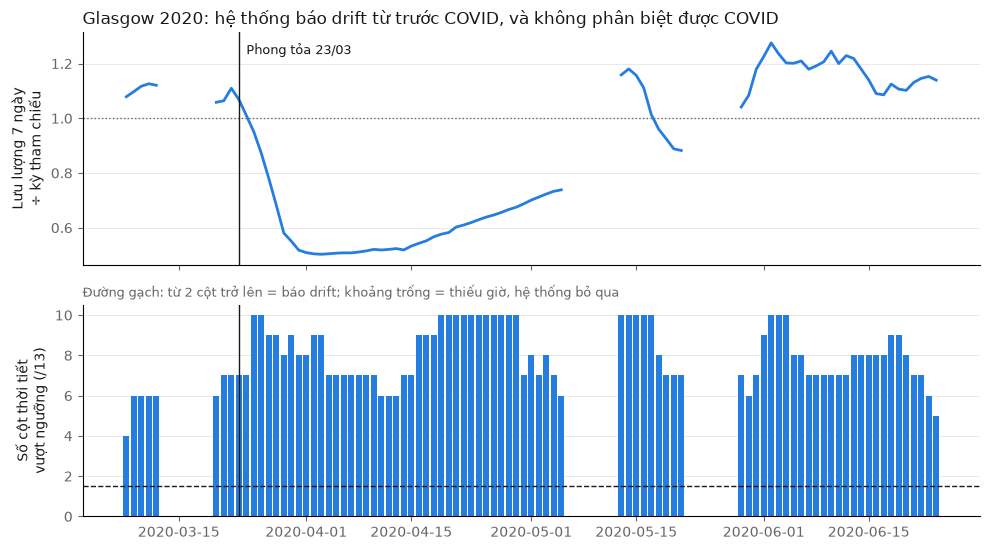

In [5]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.1, 1]})
top.plot(g.day, g.traffic_ratio, color=BLUE, lw=2)
top.axhline(1, color=MUTED, lw=1, ls=":")
top.set_ylabel("Lưu lượng 7 ngày\n÷ kỳ tham chiếu", color=INK)
top.set_title("Glasgow 2020: hệ thống báo drift từ trước COVID, và không phân biệt được COVID", loc="left", color=INK)
bottom.bar(checked.day, checked.drifted_count, width=0.8, color=BLUE)
bottom.axhline(S.drift_min_drifted_features - 0.5, color=INK, lw=1, ls="--")
bottom.set_title("Đường gạch: từ 2 cột trở lên = báo drift; khoảng trống = thiếu giờ, hệ thống bỏ qua", loc="left", fontsize=9, color=MUTED)
bottom.set_ylabel("Số cột thời tiết\nvượt ngưỡng (/13)", color=INK)
for ax in (top, bottom):
    ax.axvline(LOCKDOWN, color=INK, lw=1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
top.text(LOCKDOWN + pd.Timedelta(days=1), top.get_ylim()[1] * 0.97, "Phong tỏa 23/03", va="top", color=INK, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "E3-1-glasgow-covid-feature-drift.png", dpi=150)
plt.show()

**Đọc kết quả.**
- Hệ thống **báo drift ngay lần kiểm đầu tiên (08/03)**, hai tuần **trước** phong tỏa, khi lưu lượng vẫn **cao hơn** kỳ tham chiếu (≈ 1,1 lần). Lý do: thời tiết đầu tháng 3 khác tháng 2 (gió, nhiệt độ, điểm sương…).
- Từ đó **ngày nào cũng báo** (88/88 ngày kiểm được; khoảng trống trên hình là những ngày thiếu giờ dữ liệu nên hệ thống bỏ qua).
- Sau phong tỏa, số cột vượt ngưỡng có lúc lên 9–10, nhưng **giữa tháng 5 và đầu tháng 6 cũng lên 10** trong khi lưu lượng đã trở lại ≈ 1,1–1,2 lần tham chiếu. Con số này **đi theo thời tiết** (càng xa tháng 2 càng khác mùa), không đi theo giao thông.
- Nghĩa là: tín hiệu **có báo** trong thời gian COVID, nhưng **không phải vì COVID**. Nó không phân biệt được "giao thông thay đổi thật" với "trời đổi mùa". Người vận hành nhìn cảnh báo này không biết model có thật sự kém đi không.

### 5.1b — Dữ liệu ổn định: I‑94 qua 36 tháng

Nếu ở nơi giao thông **ổn định** mà hệ thống vẫn báo, đó là **báo nhầm**. Thử 36 mốc train khác nhau (ngày 1 hằng tháng, 2013–2017), mỗi mốc kiểm hằng ngày trong 90 ngày.

> **Đoán trước:** trong dữ liệu ổn định, bao nhiêu % ngày kiểm bị báo drift? Sau bao nhiêu ngày thì lần báo đầu tiên xuất hiện?

In [6]:
rows = []
for train_end in pd.date_range("2013-01-01", "2017-09-01", freq="MS"):
    d = daily(i94, train_end, 90)
    d = d[d.status != "skipped"]                     # I-94 có nhiều lỗ dữ liệu -> nhiều ngày bị bỏ qua
    if d.empty:
        continue
    alarms = d[d.status == "drift"]
    rows.append({"train_end": train_end.date(), "ngày kiểm được": len(d),
                 "% ngày báo drift": 100 * len(alarms) / len(d),
                 "lần báo đầu sau (ngày)": (alarms.day.min() - train_end).days if len(alarms) else None,
                 "lưu lượng ÷ tham chiếu (trung vị)": d.traffic_ratio.median()})
i94_months = pd.DataFrame(rows)
print("Số mốc train có ngày kiểm được:", len(i94_months))
i94_months.describe().loc[["mean", "min", "50%", "max"]].round(2)

Số mốc train có ngày kiểm được: 36


,ngày kiểm được,% ngày báo drift,lần báo đầu sau (ngày),lưu lượng ÷ tham chiếu (trung vị)
mean,36.89,100.0,23.89,1.02
min,3.00,100.0,7.00,0.82
50%,40.00,100.0,9.00,1.03
max,76.00,100.0,94.00,1.13


**Đọc kết quả.**
- **100% ngày kiểm được đều báo drift**, ở cả 36 mốc train, dù lưu lượng gần như không đổi (trung vị ≈ 1,0 lần kỳ tham chiếu).
- Một nửa số mốc báo ngay trong **≤ 9 ngày** sau khi train (lần kiểm đầu tiên là ngày thứ 7).
- Nếu bật tự retrain, hệ thống sẽ retrain **mỗi 72 giờ** (hết thời gian nghỉ là báo lại) — tốn tài nguyên mà không vì lý do thật.

### 5.1c — Kiểm chứng âm: khi chắc chắn **không** có drift

Có thể ai đó nói: "biết đâu thời tiết thật sự đổi". Để chắc, ta dựng một tình huống **chắc chắn không có drift**: lấy kỳ hiện tại là **7 ngày cuối nằm bên trong chính kỳ tham chiếu**. Một bộ phát hiện tốt phải gần như **không** báo.

> **Đoán trước:** bao nhiêu % lần kiểm vẫn báo drift?

In [7]:
def null_test(frame, ends):
    rows = []
    for end in ends:
        reference = frame[(frame.date_time >= end - pd.Timedelta(days=30)) & (frame.date_time < end)]
        current = reference[reference.date_time >= end - pd.Timedelta(days=7)]   # nằm trong tham chiếu
        if min(len(reference), len(current)) < S.drift_min_window_rows:
            continue
        r = calculate_feature_drift(reference, current, S.drift_psi_threshold, S.drift_js_threshold,
                                    S.drift_min_drifted_features)
        rows.append({"drift": r["summary"]["drift_detected"], "count": r["summary"]["drifted_feature_count"],
                     **{k: v["drift"] for k, v in r["features"].items()}})
    return pd.DataFrame(rows)

hcm = load("data/synthetic/TrafficVolumeData_HCM_2015_2030_synthetic.csv")
null = {"I-94 (thật)": null_test(i94, pd.date_range("2013-01-01", "2018-09-01", freq="7D")),
        "Glasgow (thật)": null_test(glasgow, pd.date_range("2019-11-01", "2023-09-01", freq="7D")),
        "Hồ Chí Minh (synthetic)": null_test(hcm, pd.date_range("2016-01-01", "2026-01-01", freq="7D"))}
pd.DataFrame({name: {"số lần kiểm": len(t), "% báo drift (lẽ ra ≈ 0%)": 100 * t.drift.mean(),
                     "số cột vượt ngưỡng (trung vị)": t["count"].median()} for name, t in null.items()}).T.round(1)

,số lần kiểm,% báo drift (lẽ ra ≈ 0%),số cột vượt ngưỡng (trung vị)
I-94 (thật),96.0,97.9,4.0
Glasgow (thật),172.0,98.3,5.0
Hồ Chí Minh (synthetic),522.0,61.3,2.0


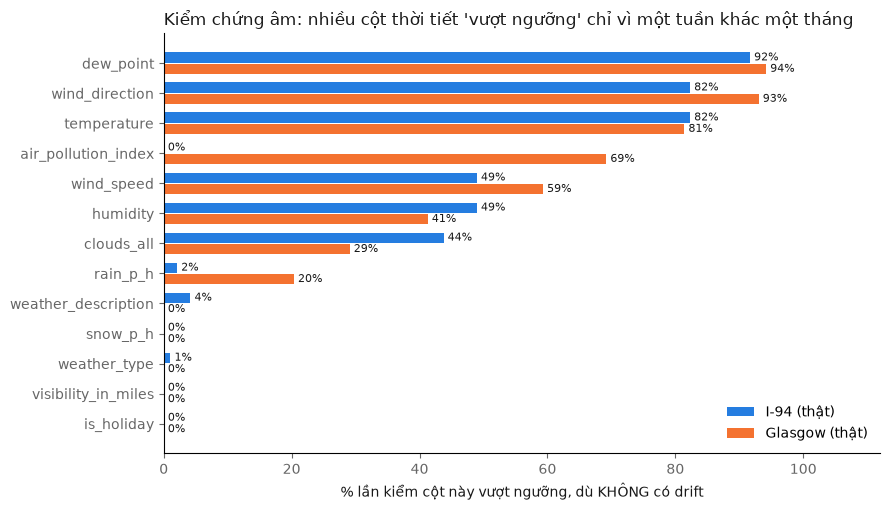

,I-94 (thật),Glasgow (thật)
is_holiday,0.0,0.0
visibility_in_miles,0.0,0.0
weather_type,1.0,0.0
snow_p_h,0.0,0.0
weather_description,4.0,0.0
rain_p_h,2.0,20.0
clouds_all,44.0,29.0
humidity,49.0,41.0
wind_speed,49.0,59.0
air_pollution_index,0.0,69.0


In [8]:
features = [c for c in null["I-94 (thật)"].columns if c not in ("drift", "count")]
share = pd.DataFrame({name: 100 * null[name][features].mean() for name in ["I-94 (thật)", "Glasgow (thật)"]})
share = share.sort_values("Glasgow (thật)")
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(share)); h = 0.38
for offset, (name, color) in zip((h / 2, -h / 2), [("I-94 (thật)", BLUE), ("Glasgow (thật)", ORANGE)]):
    bars = ax.barh(y + offset, share[name], height=h - 0.04, color=color, label=name)
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8, color=INK)
ax.set_yticks(y, share.index); ax.set_xlim(0, 112)
ax.set_xlabel("% lần kiểm cột này vượt ngưỡng, dù KHÔNG có drift", color=INK)
ax.set_title("Kiểm chứng âm: nhiều cột thời tiết 'vượt ngưỡng' chỉ vì một tuần khác một tháng", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(colors=MUTED)
fig.tight_layout(); fig.savefig(FIG / "E3-2-null-test-feature-share.png", dpi=150); plt.show()
share.round(0)

**Đọc kết quả.**
- Ngay cả khi **chắc chắn không có drift**, hệ thống vẫn báo ở **≈ 98%** lần kiểm với dữ liệu thật (I‑94, Glasgow) và ≈ 61% với dữ liệu synthetic của website.
- Nguyên nhân là cách đo, không phải dữ liệu: **thời tiết của một tuần tự nhiên khác thời tiết của cả tháng** (một tuần có thể mưa liền, gió một hướng). PSI trên 168 giờ liền nhau, chia 10 khoảng, gần như luôn vượt 0,2 với các cột như nhiệt độ, điểm sương, gió; cần chỉ 2/13 cột là đủ báo.
- Cột nào trống hoặc hằng số (ví dụ `air_pollution_index`, `visibility_in_miles` = 0 ở I‑94) thì không bao giờ vượt — chúng không giúp gì.

### 5.1d — Trên hệ thống thật (đọc DB chỉ đọc, 27/11/2026)

Bảng `drift_checks` của website (Hà Nội, Hồ Chí Minh; dataset synthetic) có **12 lần kiểm**: 3 lần bỏ qua (kỳ hiện tại chưa đủ 168 giờ), **9/9 lần còn lại đều báo drift** (4–6/13 cột), trong đó 2 lần đã kích hoạt retrain (12/11 tự động, 17/11 thủ công). Lần kiểm 25 và 27/11 của Hồ Chí Minh so tuần hiện tại với kỳ tham chiếu **tháng 12/2025** (model train đến 01/01/2026) — lệch gần một năm, khác mùa.

*Số này lấy một lần bằng truy vấn chỉ đọc trong pod API; notebook không kết nối hệ thống nên không chạy lại được ô này.*

### Tóm tắt bước 5.1

| Câu hỏi | Trả lời bằng số |
| --- | --- |
| COVID ở Glasgow có được phát hiện **vì** COVID không? | Không: báo từ 08/03 (trước phong tỏa 15 ngày), lưu lượng lúc đó còn cao hơn tham chiếu; tín hiệu không đổi khi lưu lượng tụt một nửa |
| Dữ liệu ổn định (I‑94) bị báo nhầm bao nhiêu? | 100% ngày kiểm, ở cả 36 mốc train; một nửa báo trong ≤ 9 ngày |
| Khi chắc chắn không có drift? | Vẫn báo ≈ 98% (thật), ≈ 61% (synthetic) |
| Hệ thống thật? | 9/9 lần kiểm không bị bỏ qua đều báo drift |

**Kết luận 5.1:** cách phát hiện drift hiện tại **luôn bật**, nên **không mang thông tin** về việc có nên retrain hay không. Hai lý do: (1) so **một tuần với một tháng** của các cột thời tiết vốn dao động; (2) **không nhìn số xe hay sai số model**. Đây là điểm xuất phát cho bước 5.2–5.4: tìm tín hiệu **phản ứng với COVID** nhưng **im lặng khi ổn định**.

**Bài học về phương pháp (bước 5.1)**
1. **Đo hệ thống có sẵn trước khi đề xuất cái mới**, và gọi đúng mã của nó — nếu tự viết lại, kết quả "sai" có thể do mình viết sai.
2. **Kiểm chứng âm** (tình huống chắc chắn không có hiện tượng) là cách nhanh nhất để biết một bộ phát hiện có đáng tin không: một bộ báo động kêu cả khi không có trộm thì không dùng được.
3. Một tín hiệu "có báo đúng lúc" chưa đủ; phải hỏi **nó có báo cả lúc không nên báo không**.